# Press figures: the forest and the heat of summer 2026

**notebook version**: `1` (19 Nov 2026)

## ℹ️ About this notebook

Two figures for a general audience, for example a newspaper article, from the LI-7200 years of the
CH-LAE flux record:

1. Net CO2 uptake over the day, June to September, for mild, warm and hot hours.
2. Net CO2 uptake from June to September 2026, summed from 1 June, against the years 2016-2025.

The figures use plain units (kilograms or tonnes of CO2 per hectare), local summer time and direct
labels instead of legends. Their scientific counterparts are
`95_DOCS_FIGURES/NEP_DIURNAL_BY_TA_IRGA72` and `90_OVERVIEW/FLUX_NEE_IRGA72_HOT_SUMMER_2026`.
The figures are written as PNG and SVG to `workflow/90_OVERVIEW/figures/`.

**Data used** (external data folder):

- `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/05_FPPC_IRGA72_NEE_2016-2026.09`:
  `NEE_L3.1_L3.3_CUT_50_QCF_gfXG`, the gap-filled `NEE` at the median USTAR threshold, and
  `TA_T1_47_1_HOMOGENIZED_MEASURED`, the air temperature at 47 m

Net uptake is the negative of `NEE` (`NEP`). The values include gap-filled half-hours.

## ⚙️ Settings

In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # the repository root, two levels above this notebook
OUT = ROOT / 'workflow' / '90_OVERVIEW' / 'figures'
DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
SOURCEFILE = DATADIR / '30_FLUX_POST-PROCESSING_CHAIN' / 'IRGA72' / '05_FPPC_IRGA72_NEE_2016-2026.09.parquet'
NEE = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'
TA = 'TA_T1_47_1_HOMOGENIZED_MEASURED'

MONTHS = [6, 7, 8, 9]                 # June to September
YEAR = 2026                           # the hot summer
SUMMER_TIME = 1                       # hours added to CET for local summer time (CEST)
# Temperature groups of figure 1: (label, lower limit, upper limit) in degC
GROUPS = [('Mild', 16, 20), ('Warm', 24, 28), ('Hot', 28, 50)]

# Unit conversions
UMOL_TO_KG_CO2_HA_H = 44.01e-6 * 3600 * 10          # umol m-2 s-1 -> kg CO2 per hectare and hour
UMOL_HH_TO_T_CO2_HA = 44.01e-6 * 1800 * 1e-2        # umol m-2 s-1 over a half-hour -> t CO2 per hectare

# Design
FONT = 'Segoe UI'
BG = '#FBF9F5'          # warm off-white paper
INK = '#1D2B36'         # titles and values
TEXT = '#55626B'        # subtitles and axis text
FAINT = '#8E979D'       # source line
GRID = '#E7E2D9'
MILD, WARM, HOT = '#2A9D8F', '#E9A23B', '#D1495B'
OTHER_YEARS, AVERAGE = '#CDD2D6', '#6B7780'

In [2]:
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({'font.family': FONT, 'font.size': 11, 'text.color': INK,
                     'axes.edgecolor': GRID, 'axes.labelcolor': TEXT, 'axes.facecolor': BG,
                     'figure.facecolor': BG, 'savefig.facecolor': BG,
                     'xtick.color': TEXT, 'ytick.color': TEXT, 'xtick.major.size': 0,
                     'ytick.major.size': 0, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.spines.left': False, 'figure.dpi': 100, 'savefig.dpi': 220})


def headline(fig, title, subtitle, source):
    """Newspaper-style title block at the top and source line at the bottom of the figure."""
    fig.text(0.035, 0.965, title, fontsize=18, fontweight='bold', color=INK, va='top')
    fig.text(0.035, 0.905, subtitle, fontsize=11.5, color=TEXT, va='top', linespacing=1.4)
    fig.text(0.035, 0.022, source, fontsize=8.5, color=FAINT, va='bottom', linespacing=1.4)


def save(fig, name):
    OUT.mkdir(exist_ok=True)
    for ext in ('png', 'svg'):
        fig.savefig(OUT / f'{name}.{ext}')
    print(f"written: {(OUT / name).relative_to(ROOT)}.png and .svg")


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")

Last run: 2026-11-19 17:21:33


## 📂 Load data

In [3]:
if not SOURCEFILE.exists():
    raise FileNotFoundError(f"{SOURCEFILE} is missing: this notebook needs the external data folder "
                            "and the output of IRGA72/05.")
df = pd.read_parquet(SOURCEFILE, columns=[NEE, TA]).replace(-9999, np.nan)
df.index = pd.DatetimeIndex(df.index)
assert not df.index.duplicated().any(), "duplicate timestamps"
print(f"{SOURCEFILE.name}: {df.index[0]} -> {df.index[-1]}")
d = df[df.index.month.isin(MONTHS)].copy()
assert d[NEE].notna().all(), "the gap-filled NEE has gaps in June to September"
assert d.index.max() >= pd.Timestamp(f'{YEAR}-09-30 23:00'), f"{YEAR} does not reach the end of September"
d['UPTAKE'] = -d[NEE]

05_FPPC_IRGA72_NEE_2016-2026.09.parquet: 2016-01-01 00:15:00 -> 2026-09-30 23:45:00


## 1. Net uptake over the day by air temperature

In [4]:
h = d.dropna(subset=[TA]).copy()
h['HOUR'] = h.index.hour + 0.5 + SUMMER_TIME        # hourly mean at :30, local summer time
day = []
for label, lo, hi in GROUPS:
    s = h[(h[TA] >= lo) & (h[TA] < hi)]
    m = s.groupby('HOUR')['UPTAKE'].agg(['mean', 'size'])
    m = m[m['size'] >= 20]['mean'] * UMOL_TO_KG_CO2_HA_H
    day.append(m.rename(label))
day = pd.concat(day, axis=1)
noon = h[(h['HOUR'] > 12) & (h['HOUR'] < 15)]       # 12:00-15:00 summer time
NOON = {label: noon[(noon[TA] >= lo) & (noon[TA] < hi)]['UPTAKE'].mean() * UMOL_TO_KG_CO2_HA_H
        for label, lo, hi in GROUPS}
RATIO = NOON['Hot'] / NOON['Mild']
print({k: round(v, 1) for k, v in NOON.items()}, f"hot / mild at midday: {RATIO:.0%}")
assert 0.4 < RATIO < 0.6, "the title says 'half as much'; it no longer fits"

{'Mild': np.float64(34.9), 'Warm': np.float64(26.0), 'Hot': np.float64(16.4)} hot / mild at midday: 47%


### 📊 Plot: net CO2 uptake over the day on mild, warm and hot hours

written: workflow\90_OVERVIEW\figures\PRESS_1_uptake_by_temperature.png and .svg


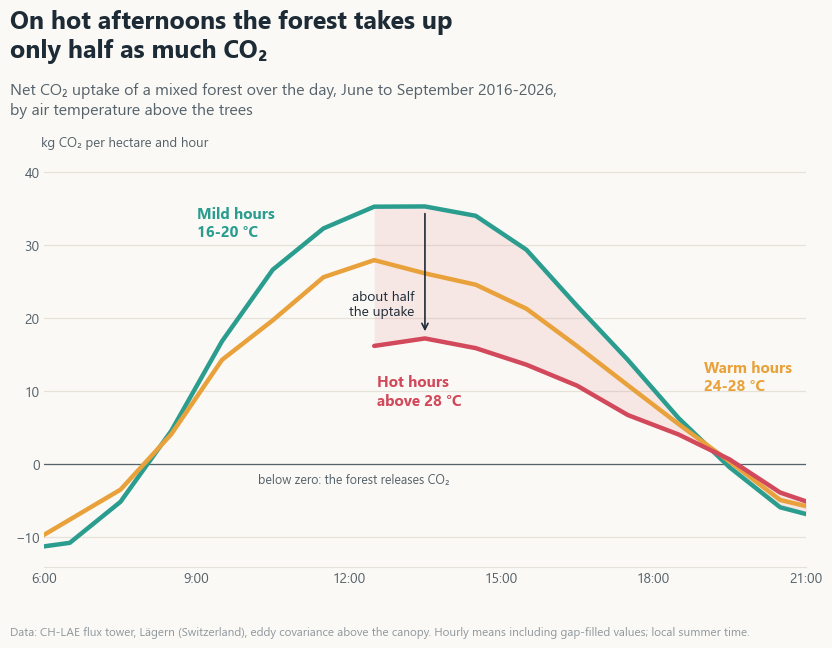

In [5]:
fig = plt.figure(figsize=(8.6, 6.6))
ax = fig.add_axes([0.075, 0.13, 0.885, 0.62])
x0, x1 = 6, 21
ax.axhline(0, color=TEXT, lw=0.9)
ax.grid(axis='y', color=GRID, lw=0.9)
ax.set_axisbelow(True)
_m, _h = day['Mild'], day['Hot']
_x = _h.dropna().index
ax.fill_between(_x, _h.loc[_x], _m.loc[_x], color=HOT, alpha=0.10, lw=0)
for label, color in zip(day.columns, (MILD, WARM, HOT)):
    s = day[label].dropna()
    ax.plot(s.index, s.values, color=color, lw=3.2, solid_capstyle='round')
# direct labels instead of a legend
LABELS_AT = {'Mild': (MILD, 'Mild hours\n16-20 °C', 9.0, 33.0),
             'Warm': (WARM, 'Warm hours\n24-28 °C', 19.0, 12.0),
             'Hot': (HOT, 'Hot hours\nabove 28 °C', 12.55, 10.0)}
for color, text, xx, yy in LABELS_AT.values():
    ax.text(xx, yy, text, color=color, fontsize=11, fontweight='bold', ha='left', va='center',
            linespacing=1.2)
# the gap at midday
_xm = 13.5
_ym, _yh = np.interp(_xm, _m.dropna().index, _m.dropna().values), np.interp(_xm, _h.dropna().index, _h.dropna().values)
ax.annotate('', xy=(_xm, _yh + 0.6), xytext=(_xm, _ym - 0.6),
            arrowprops=dict(arrowstyle='->', color=INK, lw=1.2))
ax.text(_xm - 0.2, 22, 'about half\nthe uptake', fontsize=10, color=INK, va='center', ha='right')
ax.text(10.2, -1.2, 'below zero: the forest releases CO\u2082', fontsize=9, color=TEXT, va='top')
ax.set_xlim(x0, x1)
ax.set_ylim(-14, 42)
ax.set_xticks(range(x0, x1 + 1, 3))
ax.set_xticklabels([f'{t}:00' for t in range(x0, x1 + 1, 3)])
ax.set_yticks(range(-10, 41, 10))
ax.tick_params(axis='both', labelsize=10)
ax.text(-0.005, 1.02, 'kg CO\u2082 per hectare and hour', transform=ax.transAxes, fontsize=9.5,
        color=TEXT, ha='left', va='bottom')
headline(fig, 'On hot afternoons the forest takes up\nonly half as much CO\u2082',
         'Net CO\u2082 uptake of a mixed forest over the day, June to September 2016-2026,\n'
         'by air temperature above the trees',
         'Data: CH-LAE flux tower, Lägern (Switzerland), eddy covariance above the canopy. '
         'Hourly means including gap-filled values; local summer time.')
fig.texts[0].set_position((0.035, 0.975))
fig.texts[1].set_position((0.035, 0.865))
save(fig, 'PRESS_1_uptake_by_temperature')
plt.show()

## 2. Summer 2026 against the years 2016-2025

In [6]:
cum = {}
for y, s in d['UPTAKE'].groupby(d.index.year):
    daily = s.resample('D').sum() * UMOL_HH_TO_T_CO2_HA      # daily sums give smooth curves
    c = pd.concat([pd.Series([0.0]), daily.cumsum().reset_index(drop=True)])
    c.index = np.arange(len(c), dtype=float)               # days since 1 June, 0 = start
    cum[y] = c
others = [y for y in cum if y != YEAR]
END = pd.Series({y: c.iloc[-1] for y, c in cum.items()})
AVG = END[others].mean()
grid_days = np.arange(0, 122, 0.5)
avg_curve = np.mean([np.interp(grid_days, cum[y].index, cum[y].values) for y in others], axis=0)
_aug = (pd.Timestamp(f'{YEAR}-08-01') - pd.Timestamp(f'{YEAR}-06-01')).days
AUGSEP = END[YEAR] - np.interp(_aug, cum[YEAR].index, cum[YEAR].values)
print(f"{YEAR}: {END[YEAR]:.1f} t CO2/ha; mean {min(others)}-{max(others)}: {AVG:.1f}; "
      f"lowest of the other years: {END[others].min():.1f} ({END[others].idxmin()}); "
      f"{YEAR} in August-September: {AUGSEP:+.2f}")
assert END[YEAR] < END[others].min(), "the title says weakest; it no longer fits"
assert abs(AUGSEP) < 0.3, "the subtitle says no net uptake from August; it no longer fits"

2026: 8.4 t CO2/ha; mean 2016-2025: 13.2; lowest of the other years: 8.8 (2022); 2026 in August-September: -0.07


### 📊 Plot: net CO2 uptake from 1 June, summer 2026 against 2016-2025

written: workflow\90_OVERVIEW\figures\PRESS_2_summer_2026.png and .svg


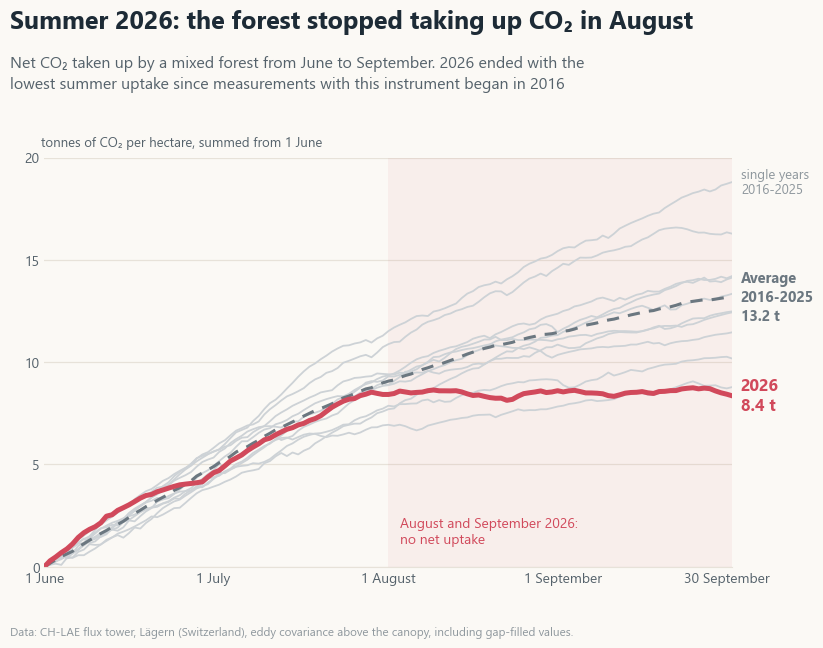

In [7]:
fig = plt.figure(figsize=(8.6, 6.6))
ax = fig.add_axes([0.075, 0.13, 0.80, 0.62])
ax.grid(axis='y', color=GRID, lw=0.9)
ax.set_axisbelow(True)
ax.axvspan(_aug, 122, color=HOT, alpha=0.06, lw=0)
for y in others:
    ax.plot(cum[y].index, cum[y].values, color=OTHER_YEARS, lw=1.3)
ax.plot(grid_days, avg_curve, color=AVERAGE, lw=2.2, ls=(0, (4, 3)))
ax.plot(cum[YEAR].index, cum[YEAR].values, color=HOT, lw=3.6, solid_capstyle='round')
ax.text(123.5, avg_curve[-1], f'Average\n2016-2025\n{AVG:.1f} t', color=AVERAGE, fontsize=10.5,
        va='center', fontweight='bold', linespacing=1.25)
ax.text(123.5, END[YEAR], f'{YEAR}\n{END[YEAR]:.1f} t', color=HOT, fontsize=12, va='center',
        fontweight='bold', linespacing=1.25)
ax.text(123.5, END[others].max(), 'single years\n2016-2025', color=FAINT, fontsize=9.5, va='center',
        linespacing=1.25)
ax.text(_aug + 2, 1.0, 'August and September 2026:\nno net uptake', color=HOT, fontsize=10,
        va='bottom', linespacing=1.3)
months = {'1 June': 0, '1 July': 30, '1 August': 61, '1 September': 92, '30 September': 121}
ax.set_xticks(list(months.values()))
ax.set_xticklabels(list(months.keys()))
ax.set_xlim(0, 122)
_top = int(np.ceil(END.max() / 5) * 5)
ax.set_ylim(0, _top)
ax.set_yticks(range(0, _top + 1, 5))
ax.tick_params(axis='both', labelsize=10)
ax.text(-0.005, 1.02, 'tonnes of CO\u2082 per hectare, summed from 1 June', transform=ax.transAxes,
        fontsize=9.5, color=TEXT, ha='left', va='bottom')
headline(fig, f'Summer {YEAR}: the forest stopped taking up CO\u2082 in August',
         f'Net CO\u2082 taken up by a mixed forest from June to September. {YEAR} ended with the\n'
         f'lowest summer uptake since measurements with this instrument began in 2016',
         'Data: CH-LAE flux tower, Lägern (Switzerland), eddy covariance above the canopy, '
         'including gap-filled values.')
fig.texts[0].set_position((0.035, 0.975))
fig.texts[1].set_position((0.035, 0.905))
save(fig, 'PRESS_2_summer_2026')
plt.show()

### 📋 Table: net uptake from June to September per year

In [8]:
display(END.round(1).rename('net uptake June-September (t CO2 per hectare)').to_frame()
        .style.set_caption("Table - net CO2 uptake from 1 June to 30 September per year, the end "
                           "points of the second figure"))

,net uptake June-September (t CO2 per hectare)
2016,12.500000
2017,10.200000
2018,12.400000
2019,18.800000
2020,14.200000
2021,13.300000
2022,8.800000
2023,11.500000
2024,14.100000
2025,16.300000


## ⏱️ Runtime

In [9]:
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}, "
      f"runtime {datetime.now() - NOTEBOOK_START}")

Finished: 2026-11-19 17:21:34, runtime 0:00:00.935647
